# Metadata Explortory Analysis

In [2]:
import IPython

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

%cd /home/jovyan/MicroOdyssey_clean

data_dir="data"
result_dir="output/01_expl_dataanalysis"



/home/jovyan/MicroOdyssey_clean


In [3]:
df_meta = pd.read_csv(f"{data_dir}/metadata.tsv", sep='\t')
df_meta.head(5)

,sample-id,collection_date,country,instrument,sample_number,delivery_mode,host_sex,diet_milk,city,latitude,longitude,urca_code,urca_description,host_id,host_age,seq_depth,age_months
0,SRR25052523,19.09.2018,usa,illumina novaseq 6000,1,csection,female,NaN,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),10,2,17325587,2.0
1,SRR25052512,20.12.2018,usa,illumina novaseq 6000,2,csection,female,mixed,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),10,6,12407450,6.0
2,SRR25052501,08.07.2019,usa,illumina novaseq 6000,3,csection,female,mixed,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),10,12,11964978,12.0
3,SRR25052458,30.06.2020,usa,illumina novaseq 6000,4,csection,female,mixed,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),10,24,10921526,24.0
4,SRR25052720,28.08.2018,usa,illumina novaseq 6000,5,vaginal,male,NaN,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),105,0,12988703,0.0


In [4]:
df_meta.columns

Index(['sample-id', 'collection_date', 'country', 'instrument',
       'sample_number', 'delivery_mode', 'host_sex', 'diet_milk', 'city',
       'latitude', 'longitude', 'urca_code', 'urca_description', 'host_id',
       'host_age', 'seq_depth', 'age_months'],
      dtype='object')

In [5]:
df_meta.shape

(234, 17)

In [6]:
df_meta["host_id"].nunique()

55

There are 55 infant hosts

In [7]:
for i in df_meta:
    print(i, df_meta[i].nunique())

sample-id 234
collection_date 113
country 1
instrument 1
sample_number 234
delivery_mode 2
host_sex 2
diet_milk 2
city 1
latitude 1
longitude 1
urca_code 1
urca_description 1
host_id 55
host_age 5
seq_depth 234
age_months 5


In [8]:
df_meta.isna().sum()

sample-id            0
collection_date      0
country              0
instrument           0
sample_number        0
delivery_mode        0
host_sex             0
diet_milk           91
city                 0
latitude             0
longitude            0
urca_code            0
urca_description     0
host_id              0
host_age             0
seq_depth            0
age_months           0
dtype: int64

91 diet values are missing

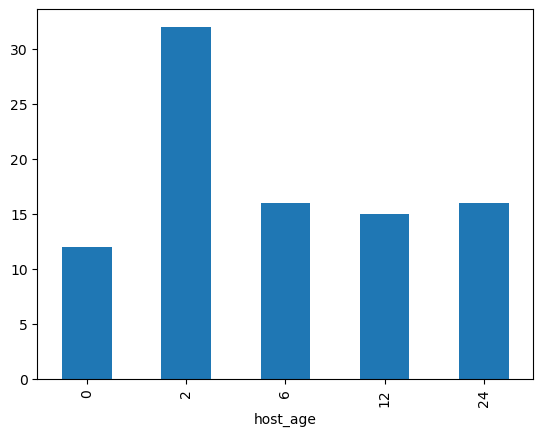

In [9]:
missing_values = df_meta["diet_milk"].isna().groupby(df_meta["host_age"]).sum().plot(kind="bar")

In [11]:
# Number of unique diet categories per infant
diet_per_infant = (
    df_meta.groupby("host_id")["diet_milk"]
    .nunique()
)

print(diet_per_infant.value_counts().sort_index())

diet_milk
0    17
1    38
Name: count, dtype: int64


In [12]:
missing_infants = df_meta.loc[
    df_meta["diet_milk"].isna(), "host_id"
].nunique()

print("Infants with at least one missing diet value:", missing_infants)

Infants with at least one missing diet value: 32


In [13]:
all_missing = (
    df_meta.groupby("host_id")["diet_milk"]
    .apply(lambda x: x.isna().all())
)

print("Infants with all diet values missing:", all_missing.sum())

Infants with all diet values missing: 17


In [14]:
delivery_sex = df_meta.groupby(["delivery_mode", "host_sex"])["host_id"].nunique()
delivery_sex

delivery_mode  host_sex
csection       female      12
               male        10
vaginal        female      15
               male        18
Name: host_id, dtype: int64

In [15]:
delivery_sex = delivery_sex.unstack()

33 were born vaginal and 22 by Csection

<Axes: xlabel='delivery_mode'>

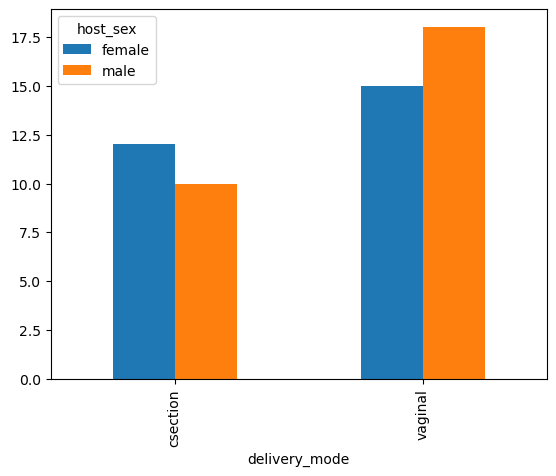

In [16]:
delivery_sex.plot(kind = "bar")

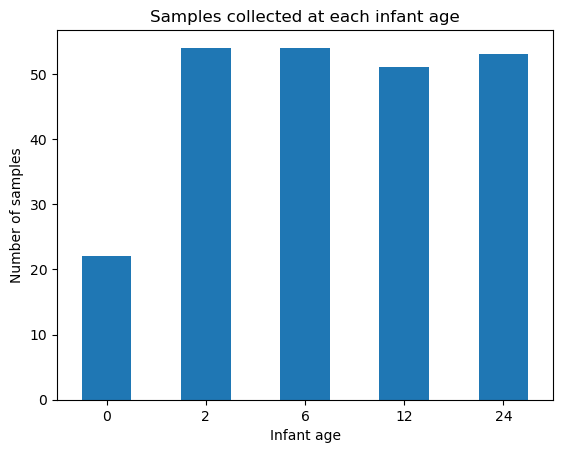

In [19]:
age_order = [0, 2, 6, 12, 24]

df_meta["host_age"].value_counts().reindex(age_order).plot(kind="bar")

plt.xlabel("Infant age")
plt.ylabel("Number of samples")
plt.title("Samples collected at each infant age")
plt.xticks(rotation=0)
plt.show()

The infants were sampled at 5 different timepoints: birth, 12 months, 24 months, 6 months and 2 months.

In [20]:
sex = df_meta.groupby("host_sex")["host_id"].nunique()
sex

host_sex
female    27
male      28
Name: host_id, dtype: int64

<Axes: xlabel='host_sex'>

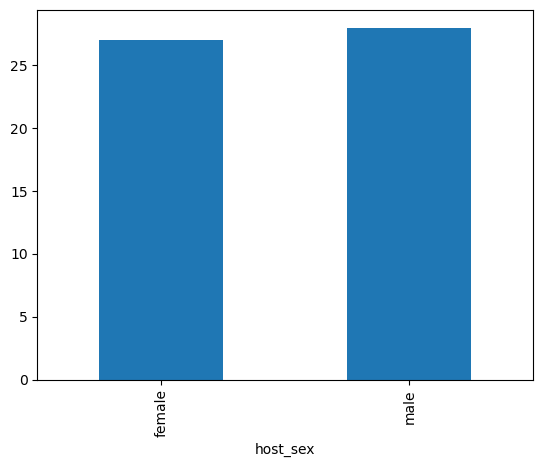

In [21]:
sex.plot(kind = "bar")

In [22]:
diet = df_meta.groupby(["diet_milk", "host_sex"])["host_id"].nunique()
diet

diet_milk  host_sex
bd         female      11
           male        11
mixed      female       9
           male         7
Name: host_id, dtype: int64

In [23]:
diet = diet.unstack()

<Axes: xlabel='diet_milk'>

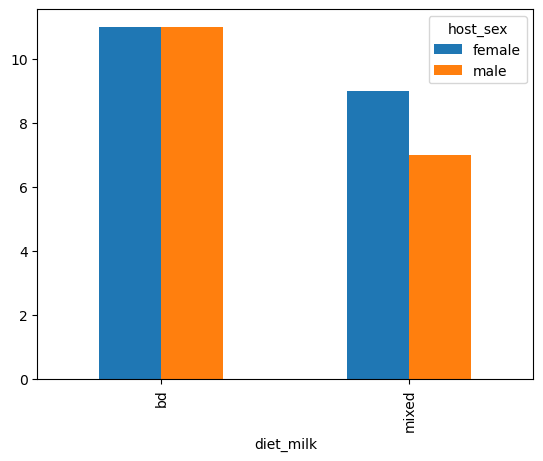

In [24]:
diet.plot(kind = "bar")

In [25]:
diet = df_meta.groupby(
    ["delivery_mode", "host_sex", "diet_milk"]
)["host_id"].nunique().unstack(fill_value=0)

diet

diet_milk               bd  mixed
delivery_mode host_sex           
csection      female     4      5
              male       4      1
vaginal       female     7      4
              male       7      6

<Axes: xlabel='delivery_mode,host_sex'>

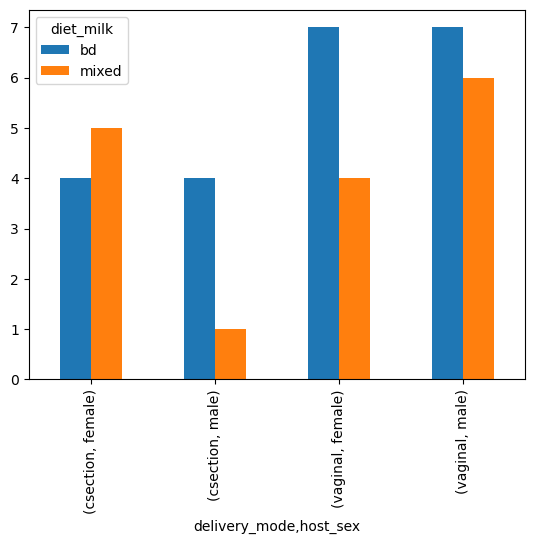

In [26]:
diet.plot(kind = "bar")